# 04. Model Training and Evaluation

## 1. Introduction

Machine learning model training is the process of teaching an algorithm to identify patterns in historical data. Model evaluation measures how well the trained model predicts outcomes for unseen data.

In this notebook, we will build regression models to predict property prices in Pune using the features prepared in the feature engineering stage.

### Objectives
- Load the cleaned dataset.
- Select the target variable and input features.
- Split the dataset into training and testing sets.
- Build a preprocessing pipeline for numerical and categorical features.
- Establish a baseline for comparison.
- Train and compare regression models.
- Evaluate performance using MAE, RMSE, and R².
- Identify a suitable candidate model for further tuning.

### Problem Statement

Given property characteristics such as area, BHK count, locality, property type, bathrooms, and floor information, predict the property's listed price.

**Problem type:** Supervised Machine Learning — Regression

**Target variable:** `price`

In [1]:
import pandas as pd
import numpy as np
from pathlib import Path

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

pd.set_option("display.max_columns", None)
pd.set_option("display.float_format", "{:,.2f}".format)

# Locate project root
project_root = Path.cwd().parent

# Load cleaned dataset
data_file = project_root / "data" / "processed" / "pune_property_cleaned.csv"
df = pd.read_csv(data_file)

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)

display(df.head())

Dataset loaded successfully!
Dataset shape: (29680, 29)


,additionalrooms,age,amenitiesavailable,amenitiesnot,area,balconies,bathroom,bhk,carpetarea,facing,floor,locality,neworold,opensides,overlooking,ownership,possesiondate,price,pricepersquare,projectname,roadfaceing,status,totalfloor,bhk_count,property_type,floor_number,road_width_feet,property_age_years,possession_date
0,NaN,2 - 3 years,"Lift Available,Car Parking,Power Backup,Indoor...","24 X 7 Security,Children's play area,Club Hous...","1,611.00",2.00,3.00,3 BHK Apartment,"1,209.00",West,"3,",Deccan Gymkhana,New,2.00,Road View,Co-Operative Society,NaN,27000000,16759,Bhansali Prive Rio,40 feet,Ready to move,6.00,3.00,Apartment,3.00,40.00,2.50,NaN
1,NaN,0 - 1 year,"Lift Available,Car Parking,Power Backup,24 X 7...","Children's play area,Sports Facility,Landscape...","1,279.00",NaN,2.00,2 BHK Apartment,NaN,NorthEast,1,Kharadi,New,NaN,NaN,Freehold,NaN,7610050,5950,Goel Ganga Platino,NaN,Ready to move,NaN,2.00,Apartment,1.00,NaN,0.50,NaN
2,NaN,0 - 1 year,"Lift Available,Car Parking,Power Backup,24 X 7...",Sports Facility,670.00,NaN,1.00,1 BHK Apartment,NaN,NorthEast,1,Sus,New,NaN,NaN,Freehold,NaN,4100000,6119,Vilas Javdekar Yashwin,NaN,Ready to move,NaN,1.00,Apartment,1.00,NaN,0.50,NaN
3,NaN,2 - 3 years,"Lift Available,Car Parking,Power Backup,24 X 7...","Sports Facility,Landscaped Gardens",956.00,NaN,2.00,2 BHK Apartment,615.00,NorthEast,1,Bavdhan,New,NaN,NaN,Freehold,NaN,5736000,6000,Rohan Ishan,NaN,Ready to move,NaN,2.00,Apartment,1.00,NaN,2.50,NaN
4,NaN,0 - 1 year,"Lift Available,Car Parking,Power Backup,24 X 7...","Club House,Swimming Pool,Sports Facility,Joggi...","1,706.00",1.00,3.00,3 BHK Apartment,"1,195.00",West,"6,",Deccan Gymkhana,New,2.00,Road View,Freehold,NaN,29002000,17000,Swojas Aavishkar,60 feet,Ready to move,9.00,3.00,Apartment,6.00,60.00,0.50,NaN


In [2]:
features = [
    "area",
    "bhk_count",
    "property_type",
    "locality",
    "bathroom",
    "balconies",
    "floor_number",
    "totalfloor",
    "property_age_years",
    "facing",
    "ownership",
    "neworold",
    "status"
]

X = df[features].copy()
y = df["price"].copy()

print("Features shape:", X.shape)
print("Target shape:", y.shape)
print("Missing target values:", y.isna().sum())
print("Non-positive prices:", (y <= 0).sum())

Features shape: (29680, 13)
Target shape: (29680,)
Missing target values: 0
Non-positive prices: 0


In [3]:
X_train, X_test, y_train, y_test = train_test_split(X,y,test_size=0.20,random_state=42)

print("Training features:", X_train.shape)
print("Testing features:", X_test.shape)
print("Training target:", y_train.shape)
print("Testing target:", y_test.shape)

Training features: (23744, 13)
Testing features: (5936, 13)
Training target: (23744,)
Testing target: (5936,)


In [4]:
numeric_features = [
    "area",
    "bhk_count",
    "bathroom",
    "balconies",
    "floor_number",
    "totalfloor",
    "property_age_years"
]

categorical_features = [
    "property_type",
    "locality",
    "facing",
    "ownership",
    "neworold",
    "status"
]

numeric_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median"))
])

categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer(transformers=[
    ("numeric", numeric_transformer, numeric_features),
    ("categorical", categorical_transformer, categorical_features)
])

print("Numerical features:", len(numeric_features))
print("Categorical features:", len(categorical_features))
print("Total selected features:", len(numeric_features) + len(categorical_features))

Numerical features: 7
Categorical features: 6
Total selected features: 13


In [5]:
baseline_model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("model", DummyRegressor(strategy="median"))
])

baseline_model.fit(X_train, y_train)

baseline_predictions = baseline_model.predict(X_test)

baseline_mae = mean_absolute_error(y_test, baseline_predictions)
baseline_rmse = np.sqrt(mean_squared_error(y_test, baseline_predictions))
baseline_r2 = r2_score(y_test, baseline_predictions)

print(f"Baseline MAE:  {baseline_mae:,.2f}")
print(f"Baseline RMSE: {baseline_rmse:,.2f}")
print(f"Baseline R²:   {baseline_r2:.4f}")

Baseline MAE:  9,478,175.46
Baseline RMSE: 18,232,431.95
Baseline R²:   -0.1285


## Model 1 — Linear Regression

In [6]:
linear_model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("model", LinearRegression())
])

# Train the model
linear_model.fit(X_train, y_train)

# Predict prices for unseen test records
linear_predictions = linear_model.predict(X_test)

# Evaluate performance
linear_mae = mean_absolute_error(y_test, linear_predictions)
linear_rmse = np.sqrt(mean_squared_error(y_test, linear_predictions))
linear_r2 = r2_score(y_test, linear_predictions)

print(f"Linear Regression MAE:  {linear_mae:,.2f}")
print(f"Linear Regression RMSE: {linear_rmse:,.2f}")
print(f"Linear Regression R²:   {linear_r2:.4f}")

Linear Regression MAE:  5,723,173.50
Linear Regression RMSE: 9,397,729.86
Linear Regression R²:   0.7002


## Model 2 — Random Forest Regressor

In [7]:
random_forest_model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("model", RandomForestRegressor(
        n_estimators=100,
        random_state=42,
        n_jobs=-1
    ))
])

# Train the model
random_forest_model.fit(X_train, y_train)

# Predict prices for unseen test records
rf_predictions = random_forest_model.predict(X_test)

# Evaluate performance
rf_mae = mean_absolute_error(y_test, rf_predictions)
rf_rmse = np.sqrt(mean_squared_error(y_test, rf_predictions))
rf_r2 = r2_score(y_test, rf_predictions)

print(f"Random Forest MAE:  {rf_mae:,.2f}")
print(f"Random Forest RMSE: {rf_rmse:,.2f}")
print(f"Random Forest R²:   {rf_r2:.4f}")

Random Forest MAE:  2,063,410.31
Random Forest RMSE: 4,407,216.77
Random Forest R²:   0.9341


## Model Comparison

In [8]:
comparison = pd.DataFrame([
    {
        "Model": "Baseline (Median)",
        "MAE": baseline_mae,
        "RMSE": baseline_rmse,
        "R2": baseline_r2
    },
    {
        "Model": "Linear Regression",
        "MAE": linear_mae,
        "RMSE": linear_rmse,
        "R2": linear_r2
    },
    {
        "Model": "Random Forest",
        "MAE": rf_mae,
        "RMSE": rf_rmse,
        "R2": rf_r2
    }
])

comparison = comparison.sort_values("MAE").reset_index(drop=True)

display(comparison.round(4))

,Model,MAE,RMSE,R2
0,Random Forest,"2,063,410.31","4,407,216.77",0.93
1,Linear Regression,"5,723,173.50","9,397,729.86",0.70
2,Baseline (Median),"9,478,175.46","18,232,431.95",-0.13


## Initial Model Comparison — Results and Conclusion

Three regression approaches were evaluated on the same held-out test set: a median baseline, Linear Regression, and Random Forest Regressor.

The Random Forest model achieved the lowest Mean Absolute Error (MAE) and Root Mean Squared Error (RMSE), along with the highest R² score among the three models.

Linear Regression also improved upon the baseline, indicating that the selected property features contain useful predictive information.

Based on these initial results, Random Forest is selected as the leading candidate for further evaluation and hyperparameter tuning.

However, these results do not yet establish that the model is ready for deployment. Further checks are required to assess overfitting, prediction errors across different price ranges, and model generalization.

The current results will be used as the benchmark for subsequent experiments.

In [9]:
# Predict on both training and testing data
rf_train_predictions = random_forest_model.predict(X_train)
rf_test_predictions = random_forest_model.predict(X_test)

# Calculate metrics for training data
train_mae = mean_absolute_error(y_train, rf_train_predictions)
train_rmse = np.sqrt(mean_squared_error(y_train, rf_train_predictions))
train_r2 = r2_score(y_train, rf_train_predictions)

# Calculate metrics for testing data
test_mae = mean_absolute_error(y_test, rf_test_predictions)
test_rmse = np.sqrt(mean_squared_error(y_test, rf_test_predictions))
test_r2 = r2_score(y_test, rf_test_predictions)

# Display comparison
overfitting_check = pd.DataFrame({
    "Dataset": ["Training", "Testing"],
    "MAE": [train_mae, test_mae],
    "RMSE": [train_rmse, test_rmse],
    "R2": [train_r2, test_r2]
})

display(overfitting_check.round(4))

,Dataset,MAE,RMSE,R2
0,Training,"796,689.24","1,967,721.09",0.99
1,Testing,"2,063,410.31","4,407,216.77",0.93


In [10]:
# Compare actual and predicted prices
prediction_results = pd.DataFrame({
    "Actual Price": y_test.to_numpy(),
    "Predicted Price": rf_test_predictions
})

prediction_results["Absolute Error"] = (
    prediction_results["Actual Price"]
    - prediction_results["Predicted Price"]
).abs()

prediction_results["Percentage Error"] = (
    prediction_results["Absolute Error"]
    / prediction_results["Actual Price"]
    * 100
)

display(prediction_results.head(10).round(2))

print(
    "Median absolute error:",
    f"{prediction_results['Absolute Error'].median():,.2f}"
)

print(
    "90th percentile absolute error:",
    f"{prediction_results['Absolute Error'].quantile(0.90):,.2f}"
)

,Actual Price,Predicted Price,Absolute Error,Percentage Error
0,8100000,"13,250,400.00","5,150,400.00",63.59
1,30000000,"39,803,864.00","9,803,864.00",32.68
2,6000000,"6,027,000.00","27,000.00",0.45
3,8500000,"10,644,500.00","2,144,500.00",25.23
4,16000000,"9,930,963.36","6,069,036.64",37.93
5,4200000,"4,386,407.00","186,407.00",4.44
6,2662200,"2,944,485.45","282,285.45",10.60
7,9500000,"9,770,130.00","270,130.00",2.84
8,33000000,"35,889,480.00","2,889,480.00",8.76
9,27200000,"37,456,537.50","10,256,537.50",37.71


Median absolute error: 822,206.66
90th percentile absolute error: 5,131,566.99


## Visualizing Model Performance

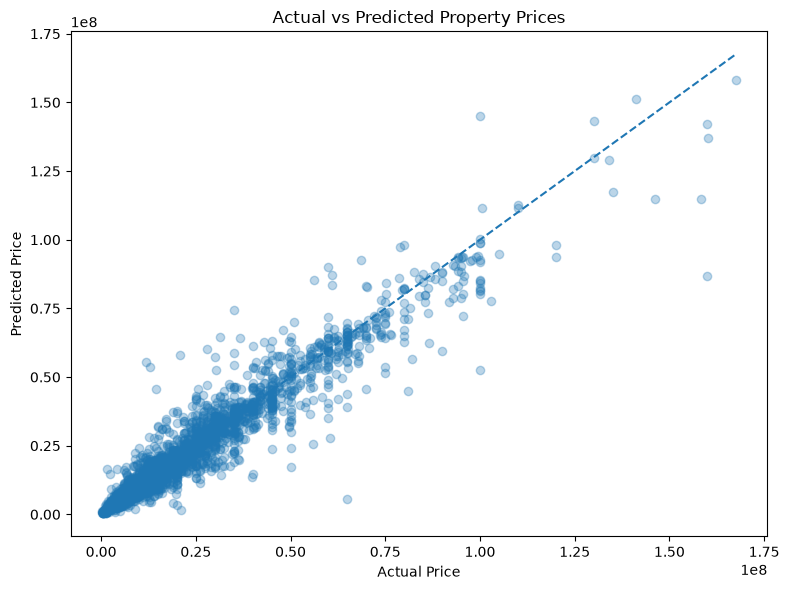

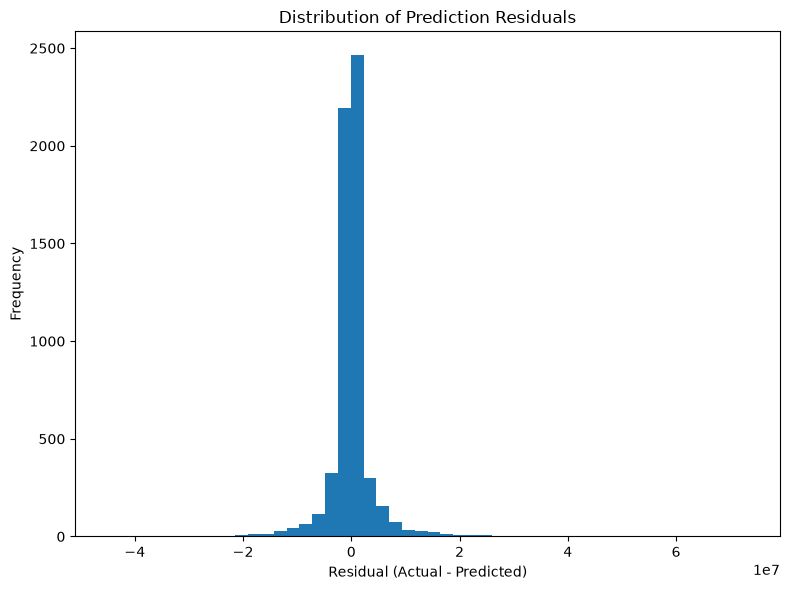

,Price Range,property_count,MAE,Median_Absolute_Error
0,Up to 50 lakh,1142,"598,306.62","374,658.47"
1,50 lakh–1 crore,2300,"903,213.27","582,735.22"
2,1–2 crore,1313,"2,207,730.79","1,377,250.00"
3,Above 2 crore,1181,"5,579,167.14","3,415,000.00"


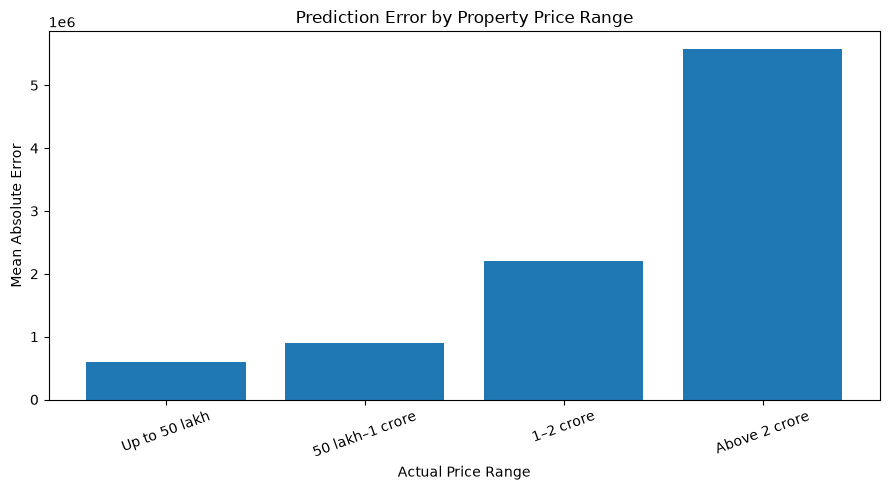

In [11]:
import matplotlib.pyplot as plt

# 1. Actual vs predicted prices
plt.figure(figsize=(8, 6))
plt.scatter(y_test, rf_test_predictions, alpha=0.3)

min_price = min(y_test.min(), rf_test_predictions.min())
max_price = max(y_test.max(), rf_test_predictions.max())

plt.plot(
    [min_price, max_price],
    [min_price, max_price],
    linestyle="--"
)

plt.xlabel("Actual Price")
plt.ylabel("Predicted Price")
plt.title("Actual vs Predicted Property Prices")
plt.tight_layout()
plt.show()


# 2. Residual distribution
residuals = y_test.to_numpy() - rf_test_predictions

plt.figure(figsize=(8, 6))
plt.hist(residuals, bins=50)
plt.xlabel("Residual (Actual - Predicted)")
plt.ylabel("Frequency")
plt.title("Distribution of Prediction Residuals")
plt.tight_layout()
plt.show()


# 3. Absolute error by actual price range
error_analysis = pd.DataFrame({
    "Actual Price": y_test.to_numpy(),
    "Predicted Price": rf_test_predictions
})

error_analysis["Absolute Error"] = (
    error_analysis["Actual Price"]
    - error_analysis["Predicted Price"]
).abs()

error_analysis["Price Range"] = pd.cut(
    error_analysis["Actual Price"],
    bins=[0, 5_000_000, 10_000_000, 20_000_000, float("inf")],
    labels=["Up to 50 lakh", "50 lakh–1 crore",
            "1–2 crore", "Above 2 crore"],
    include_lowest=True
)

range_summary = error_analysis.groupby(
    "Price Range", observed=False
).agg(
    property_count=("Absolute Error", "size"),
    MAE=("Absolute Error", "mean"),
    Median_Absolute_Error=("Absolute Error", "median")
).reset_index()

display(range_summary.round(2))

plt.figure(figsize=(9, 5))
plt.bar(
    range_summary["Price Range"].astype(str),
    range_summary["MAE"]
)
plt.xlabel("Actual Price Range")
plt.ylabel("Mean Absolute Error")
plt.title("Prediction Error by Property Price Range")
plt.xticks(rotation=20)
plt.tight_layout()
plt.show()

### 15. Error Analysis by Property Price Range

The Random Forest model's prediction error varies across property price ranges. The lowest MAE is observed in the group priced up to 50 lakh, while the highest MAE is observed in the group above 2 crore.

This indicates that prediction errors tend to increase for higher-priced properties in this test set. Possible contributing factors include differences in property characteristics, locality, and the availability of representative training examples.

The median absolute error is lower than the MAE in every price group, suggesting that some large prediction errors are increasing the average error. Further investigation is required before deciding whether to transform the target, improve the features, or tune the model.

**Conclusion:** The Random Forest model performs better on lower-priced properties in absolute monetary terms. Model tuning and further error analysis will help determine whether its performance can be improved.